# Classification d’images histologiques du sein

## 1. Présentation du projet

Le projet `breast_cancer_ML` étudie la classification automatique de fragments d’images histologiques du sein. L’objectif est de distinguer les fragments annotés comme présentant un carcinome canalaire infiltrant (*Invasive Ductal Carcinoma*, IDC) de ceux annotés comme ne présentant pas d’IDC.

**Problématique : un réseau de neurones convolutif (CNN) peut-il apprendre à distinguer les fragments IDC des fragments non-IDC à partir de leurs caractéristiques visuelles ?**

Il s’agit d’un problème d’apprentissage supervisé à deux classes : le modèle reçoit une image et apprend à prédire son étiquette à partir d’exemples annotés. La prédiction concerne un fragment d’image, et non un diagnostic global à l’échelle d’un patient.

Ce notebook constitue le fil conducteur du projet : présentation des données, préparation, construction d’un modèle avec TensorFlow/Keras, entraînement et analyse des résultats. Le suivi des expériences s’appuie sur Weights & Biases (W&B).

## 2. Présentation du dataset

Les observations sont des fragments d’images (*patchs*) histologiques répartis en deux catégories : `IDC` et `non-IDC`. Le code actuel charge les images depuis `breast_cancer_ML/breast-cancer`, un chemin relatif au répertoire d’exécution. Si le notebook est exécuté depuis la racine du dépôt, ce chemin devra être adapté en `./breast-cancer`.

L’organisation attendue, cohérente avec celle documentée dans `models_louis.ipynb`, est la suivante :

```text
breast-cancer/
├── IDC/       # Fragments annotés IDC
└── non-IDC/   # Fragments annotés sans IDC
```

| Caractéristique | Description |
| --- | --- |
| Unité d’observation | Un fragment d’image histologique |
| Entrée du modèle | Image couleur RGB chargée au format 50 × 50 pixels |
| Cible | Classe du fragment : IDC ou non-IDC |
| Prétraitement | Normalisation des pixels de [0, 255] vers [0, 1] par `Rescaling` |
| Chargement | Lots de 64 images, graine fixée à 42 |
| Découpage configuré | 80 % pour l’entraînement et 20 % pour la validation |

### Effectifs et provenance

Les sorties sauvegardées de `models_louis.ipynb` indiquent **275 222 images**, dont 220 178 pour l’entraînement et 55 044 pour la validation. Ces nombres sont des repères issus d’une précédente exécution de cet autre notebook ; ils ne constituent pas un comptage réalisé dans `project.ipynb`. Ils devront être vérifiés au chargement. La taille 50 × 50 est celle demandée par le code, et non une vérification des dimensions originales des fichiers.

La source exacte, la référence et la licence du dataset, le nombre de patients ainsi que les effectifs par classe restent à documenter. La répartition par classe permettra notamment d’évaluer un éventuel déséquilibre des données.

### Encodage des classes

Les étiquettes numériques sont déduites des sous-dossiers lors du chargement. Dans `models_louis.ipynb`, l’ordre enregistré est `['IDC', 'non-IDC']`, soit **IDC = 0 et non-IDC = 1**. Il faudra vérifier `train_ds.class_names` ici avant d’interpréter les prédictions. Pour les futures métriques ciblant IDC, la classe d’intérêt devra être explicitement définie à partir de cette correspondance.

## 3. Prétraitement — récupération, regroupement et nettoyage

### 3.1. Récupération et organisation initiale

Les données ont été récupérées sous forme d’une archive ZIP (`archive.zip`, présente dans l’espace de travail). L’adresse de téléchargement et la référence de cette archive restent à renseigner. À l’origine, les images étaient réparties dans de nombreux dossiers patients, chacun contenant des sous-dossiers de classe. L’arborescence ci-dessous illustre cette organisation :

```text
dataset/
├── patient_A/
│   ├── 0/    # non-IDC
│   └── 1/    # IDC
└── patient_B/
    ├── 0/
    └── 1/
```

### 3.2. Regroupement des images par classe

Le script [regrouper_images.ps1](../scripts/regrouper_images.ps1) parcourt une archive ZIP ou un dossier extrait, repère les répertoires `0` et `1`, puis copie les images vers deux dossiers communs. Cette opération rassemble les images de tous les patients par classe pour faciliter leur chargement par Keras. Le script conserve la source et ajoute un suffixe (`__1`, `__2`, etc.) lorsqu’un nom de fichier existe déjà dans la destination, afin de ne pas écraser une image.

Le regroupement produit une étape intermédiaire avec des noms numériques ; l’organisation retenue pour l’entraînement utilise ensuite les noms explicites `non-IDC` et `IDC` :

```text
images_regroupees/           breast-cancer/
├── 0/  (non-IDC)    →       ├── non-IDC/
└── 1/  (IDC)        →       └── IDC/
```

Le renommage final n’est pas réalisé par les quatre scripts disponibles : ceux-ci attendent encore les sous-dossiers `0` et `1`. Le nettoyage décrit ci-dessous intervient donc sur cette structure intermédiaire.

### 3.3. Nettoyage du dataset

Les scripts de préparation se trouvent dans `../scripts/`, à côté du dépôt. Ils couvrent les opérations suivantes :

| Étape | Script | Traitement |
| --- | --- | --- |
| Doublons | [supprimer_doublons_images.ps1](../scripts/supprimer_doublons_images.ps1) | Compare la taille et l’empreinte SHA-256 des fichiers dans chaque classe ; conserve un exemplaire de chaque contenu identique. |
| Contrôle des dimensions | [compter_dimensions_images.ps1](../scripts/compter_dimensions_images.ps1) | Vérifie les dimensions attendues de 50 × 50 pixels, distingue les images de dimensions différentes des fichiers illisibles et peut exporter un rapport CSV. |
| Retrait des images non conformes | [supprimer_images_non_conformes.ps1](../scripts/supprimer_images_non_conformes.ps1) | Relit le rapport CSV, vérifie à nouveau les dimensions et permet de supprimer les images qui ne font pas 50 × 50 pixels. |

La déduplication porte sur des **fichiers identiques au sein d’une même classe** : elle ne recherche ni les images simplement ressemblantes, ni les doublons entre les deux classes. Le contrôle des dimensions ne modifie pas les images ; le script de suppression retire les images de taille incorrecte au lieu de les redimensionner. Les fichiers illisibles sont signalés et conservés par ce dernier script.

Les deux scripts de suppression fonctionnent en simulation par défaut ; l’option `-Supprimer` applique le nettoyage. Les scripts décrivent la procédure, mais aucun bilan d’exécution n’est fourni ici pour chiffrer les suppressions réellement effectuées. Les effectifs avant/après nettoyage et par classe restent donc à consigner.

### 3.4. Conséquences pour l’entraînement

Le résultat est une organisation simple, avec un dossier par classe. Attention : les codes d’origine (`0 = non-IDC`, `1 = IDC`) ne sont pas nécessairement ceux attribués après renommage. Avec l’ordre `['IDC', 'non-IDC']` observé dans le notebook de Louis, Keras attribue `0 = IDC` et `1 = non-IDC`. Il faut donc toujours vérifier `train_ds.class_names`.

Le regroupement supprime le niveau « patient » de l’arborescence. Les noms de fichiers sont conservés, sauf ajout éventuel d’un suffixe ; il faudra vérifier qu’ils permettent de retrouver les identifiants patients ou conserver une table de correspondance pour réaliser un découpage par patient. Enfin, la normalisation des pixels dans [0, 1] est effectuée dans le modèle, après cette préparation des fichiers.

## 4. Démarche expérimentale

La démarche prévue est de vérifier les données et leurs étiquettes, visualiser des exemples, entraîner un CNN de référence, puis analyser ses performances et ses erreurs. Les paramètres et les métriques d’entraînement sont suivis dans W&B pour faciliter la comparaison des expériences.

**État actuel du code.** Le chargement réserve 20 % des images à la validation. Le modèle est entraîné pendant 14 époques, avec l’optimiseur Adam et une perte d’entropie croisée adaptée aux deux sorties du réseau. La métrique configurée est l’exactitude (*accuracy*). Aucun jeu de test indépendant ni découpage par patient n’est actuellement implémenté.

**Évaluation à compléter.** Une séparation par patient devra être mise en place si les identifiants sont disponibles, afin d’éviter que des fragments d’un même patient apparaissent dans plusieurs ensembles. Un jeu de test indépendant permettra ensuite d’évaluer le modèle retenu.

L’analyse prévue comprendra les courbes d’apprentissage, la matrice de confusion, la précision, le rappel et le score F1 pour IDC, ainsi que l’AUC ROC calculée à partir des scores de cette classe. Ces indicateurs compléteront l’accuracy, notamment si les classes sont déséquilibrées.

## 5. Implémentation — modèle de référence

Les cellules suivantes sont à exécuter dans l’ordre, des imports à la compilation.

### 5.1. Imports

`tensorflow` fournit le chargement des images et les couches du réseau via Keras. `wandb` assure le suivi des expériences. `numpy`, `matplotlib` et `seaborn` sont conservés pour les futures analyses et visualisations ; ils ne sont pas encore utilisés ci-dessous.


In [5]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import wandb


### 5.2. Paramètres

Les constantes définissent la taille des images (50 × 50), le nombre de classes (2) et la part réservée à la validation (20 %). `PARAMETERS` centralise les hyperparamètres transmis à W&B.

- `conv_filters` et `conv_kernel_size` : nombre de filtres et taille des noyaux des convolutions.
- `activation_conv`, `layer_1` et `activation_1` : activations et taille de la couche dense intermédiaire.
- `batch_size`, `epoch` et `seed` : taille des lots, nombre de passages sur les données et graine du découpage.
- `optimizer` et `metric` : optimiseur et métrique utilisés à la compilation.

Dans le code actuel, `learning_rate` est enregistré mais pas transmis explicitement à Adam ; `dropout_1` est enregistré sans couche Dropout associée. `loss` et `normalization` décrivent des choix écrits directement dans le code. Modifier ces champs seuls ne modifie donc pas ces éléments du modèle. La graine du chargement ne garantit pas à elle seule la reproductibilité de tout l’entraînement.


In [6]:
IMG_HEIGHT = 50
IMG_WIDTH = 50
NUM_CLASSES = 2
VALIDATION_SPLIT = 0.2

PARAMETERS = {
    "conv_filters": [64, 64, 128],
    "conv_kernel_size": 3,
    "activation_conv": "leaky_relu",
    "layer_1": 128,
    "activation_1": "relu",
    "dropout_1": 0,
    "optimizer": "adam",
    "learning_rate": 0.001,
    "loss": "SparseCategoricalCrossentropy",
    "metric": "accuracy",
    "epoch": 4,
    "batch_size": 64,
    "seed": 42,
    "normalization": "Rescaling(1.0 / 255)",
}


### 5.3. Suivi de l’expérience avec W&B

`wandb.init` ouvre une expérience nommée `louis_run_16` dans le projet `breast-cancer-ML` et enregistre les paramètres précédents. `wandb.config` fournit ensuite les valeurs utilisées par les cellules suivantes. Cette étape peut demander une authentification W&B ; elle initialise le suivi sans entraîner le réseau.


In [7]:
wandb.init(
    project="breast-cancer-ML",
    name="louis_run_19",
    config=PARAMETERS,
)

config = wandb.config


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


### 5.4. Chargement du dataset

`image_dataset_from_directory` lit les images en RGB dans les sous-dossiers de classe et leur associe des étiquettes entières. Les images sont chargées au format 50 × 50 pixels et regroupées en lots de 64.

Les deux appels utilisent le même dossier, la même graine et la même proportion de validation : `subset="training"` sélectionne les 80 % pour l’apprentissage et `subset="validation"` les 20 % restants. Ce découpage est effectué par image, sans regroupement par patient, et ne crée pas de jeu de test.

Le chemin est relatif au répertoire d’exécution : depuis la racine du dépôt, adapter `breast_cancer_ML/breast-cancer` en `./breast-cancer`. Vérifier `train_ds.class_names` pour connaître la correspondance entre classes et étiquettes. La normalisation des pixels sera effectuée dans le modèle.


In [8]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    "breast-cancer",
    batch_size=config.batch_size,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    seed=config.seed,
    validation_split=VALIDATION_SPLIT,
    subset="training"
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    "breast-cancer",
    batch_size=config.batch_size,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    seed=config.seed,
    validation_split=VALIDATION_SPLIT,
    subset="validation"
)


Found 275222 files belonging to 2 classes.
Using 220178 files for training.


E0000 00:00:1795556115.588230    4495 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1795556115.588715    5225 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1795556115.604457    4495 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Found 275222 files belonging to 2 classes.
Using 55044 files for validation.


### 5.5. Construction du CNN

`Sequential` assemble les couches dans leur ordre d’application :

1. `Rescaling(1.0 / 255)` normalise les pixels dans [0, 1].
2. Trois blocs `Conv2D` puis `MaxPooling2D` apprennent des motifs et réduisent les dimensions spatiales. Les convolutions utilisent ici 64, 64 et 128 filtres.
3. `Flatten` transforme les cartes de caractéristiques en un vecteur.
4. Une couche dense de 128 neurones combine ces caractéristiques.
5. La couche finale produit deux scores bruts, ou **logits**, un par classe. Elle ne comporte pas de softmax : la fonction de perte en tiendra compte.

Cette cellule définit l’architecture sans lancer l’apprentissage.


In [9]:
model = tf.keras.Sequential(
    [
        tf.keras.layers.Rescaling(1.0 / 255),
        tf.keras.layers.Conv2D(config.conv_filters[0], config.conv_kernel_size, activation=config.activation_conv),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(config.conv_filters[1], config.conv_kernel_size, activation=config.activation_conv),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(config.conv_filters[2], config.conv_kernel_size, activation=config.activation_conv),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(config.layer_1, activation=config.activation_1),
        tf.keras.layers.Dense(NUM_CLASSES),
    ]
)


### 5.6. Compilation du modèle

`model.compile` configure le futur entraînement :

- **Optimiseur :** Adam, sélectionné via `config.optimizer`, mettra à jour les poids. Ses paramètres par défaut sont utilisés.
- **Perte :** `SparseCategoricalCrossentropy` compare les étiquettes entières aux sorties du réseau. `from_logits=True` indique que les scores ne sont pas encore des probabilités.
- **Métrique :** `accuracy` mesure la proportion de prédictions correctes. Elle sert au suivi ; la perte guide l’optimisation.

À ce stade, le modèle est configuré pour apprendre. Aucun entraînement n’a encore été lancé.


In [10]:
model.compile(
    optimizer=config.optimizer,
    loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[config.metric],
)


## 6. Entraînement

Cette cellule reste séparée pour préparer et compiler le modèle avant de lancer le calcul. `model.fit` entraîne le réseau pendant le nombre d’époques configuré et évalue ses performances sur la validation à chaque époque. `history` conserve les métriques. Les callbacks W&B transmettent les métriques et prennent en charge la sauvegarde du modèle. Le code est conservé pour la prochaine étape.


In [11]:
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=config.epoch,
    callbacks=[
        wandb.keras.WandbMetricsLogger(log_freq=5),
        wandb.keras.WandbModelCheckpoint("models.keras")
    ]
)


Epoch 1/4


/home/vincent/5A_CPE/ML/.venv312/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


   3/3441 ━━━━━━━━━━━━━━━━━━━━ 2:01 35ms/step - accuracy: 0.7135 - loss: 0.6197 

E0000 00:00:1795556120.465704    4495 meta_optimizer.cc:967] remapper failed: INVALID_ARGUMENT: Mutation::Apply error: fanout 'StatefulPartitionedCall/gradient_tape/sequential_1/conv2d_1/LeakyRelu/LeakyReluGrad' exist for missing node 'StatefulPartitionedCall/sequential_1/conv2d_1/BiasAdd'.


3441/3441 ━━━━━━━━━━━━━━━━━━━━ 120s 35ms/step - accuracy: 0.8342 - loss: 0.3858 - val_accuracy: 0.8484 - val_loss: 0.3493
Epoch 2/4
3441/3441 ━━━━━━━━━━━━━━━━━━━━ 112s 33ms/step - accuracy: 0.8550 - loss: 0.3419 - val_accuracy: 0.8605 - val_loss: 0.3284
Epoch 3/4
3441/3441 ━━━━━━━━━━━━━━━━━━━━ 116s 34ms/step - accuracy: 0.8622 - loss: 0.3249 - val_accuracy: 0.8608 - val_loss: 0.3252
Epoch 4/4
3441/3441 ━━━━━━━━━━━━━━━━━━━━ 114s 33ms/step - accuracy: 0.8680 - loss: 0.3136 - val_accuracy: 0.8625 - val_loss: 0.3225


## 7. Courbes d’apprentissage

Ces graphiques comparent la perte et l’accuracy sur l’entraînement et la validation à chaque époque. Exécuter cette section après la cellule d’entraînement : elle utilise `history`, sans réentraîner le modèle.

**Comment les lire ?** Une baisse des deux pertes suggère que le modèle progresse sur les deux ensembles. Si la perte d’entraînement baisse tandis que celle de validation augmente durablement, cela suggère du surapprentissage. Des performances faibles sur les deux ensembles peuvent indiquer un apprentissage insuffisant. Une seule fluctuation ne suffit pas à conclure.

L’époque de perte de validation minimale est un repère : les évaluations suivantes utilisent les **poids de la dernière époque**, sans restaurer automatiquement ceux de cette meilleure époque.

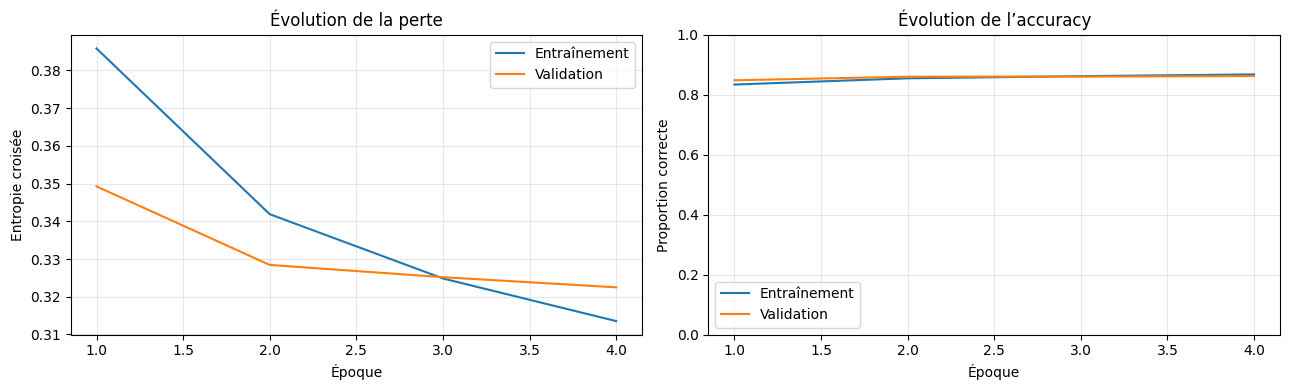

Perte de validation minimale : 0.3225, époque 4.
Dernière époque : accuracy entraînement 86.80%, validation 86.25%.


In [12]:
metrics = history.history
required = ("loss", "val_loss", "accuracy", "val_accuracy")
if any(key not in metrics for key in required) or not history.epoch:
    raise ValueError("Entraîner le modèle avec accuracy et validation avant de tracer les courbes.")

epochs = np.asarray(history.epoch) + 1
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, key, title, ylabel in [
    (axes[0], "loss", "Évolution de la perte", "Entropie croisée"),
    (axes[1], "accuracy", "Évolution de l’accuracy", "Proportion correcte"),
]:
    ax.plot(epochs, metrics[key], label="Entraînement")
    ax.plot(epochs, metrics["val_" + key], label="Validation")
    ax.set(title=title, xlabel="Époque", ylabel=ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

best_index = int(np.argmin(metrics["val_loss"]))
print(f"Perte de validation minimale : {metrics['val_loss'][best_index]:.4f}, époque {epochs[best_index]}.")
print(f"Dernière époque : accuracy entraînement {metrics['accuracy'][-1]:.2%}, "
      f"validation {metrics['val_accuracy'][-1]:.2%}.")


## 8. Évaluation sur la validation

On parcourt la validation une seule fois pour cumuler la perte et la matrice de confusion, sans conserver toutes les images en mémoire. Les labels et prédictions sont traités **dans le même lot**, ce qui évite un décalage si les images sont mélangées entre deux parcours.

La classe positive est IDC, repérée dans `validation_ds.class_names` plutôt que supposée égale à 1. Le score maximal (`argmax`) détermine la classe prédite. Les pixels ne sont pas normalisés une seconde fois : la couche `Rescaling` du modèle s’en charge.

Les mesures concernent le jeu de validation déjà utilisé pendant l’entraînement ; elles ne constituent pas une évaluation sur un test indépendant. Recalculer cette section après chaque nouvel entraînement.

In [13]:
class_names = list(validation_ds.class_names)
if len(class_names) != 2 or set(class_names) != {"IDC", "non-IDC"}:
    raise ValueError(f"Classes attendues : IDC et non-IDC ; classes trouvées : {class_names}")
idc_index = class_names.index("IDC")
non_idc_index = class_names.index("non-IDC")
print("Correspondance des classes :", dict(enumerate(class_names)))

cm = np.zeros((2, 2), dtype=np.int64)
loss_sum = 0.0
n_images = 0
loss_per_image = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True, reduction="none"
)
for images, labels in validation_ds:
    logits = model(images, training=False)
    predicted = tf.argmax(logits, axis=1, output_type=tf.int32)
    cm += tf.math.confusion_matrix(
        labels, predicted, num_classes=2, dtype=tf.int64
    ).numpy()
    loss_sum += float(tf.reduce_sum(loss_per_image(labels, logits)).numpy())
    n_images += int(tf.size(labels).numpy())

if n_images == 0:
    raise ValueError("Le jeu de validation est vide.")

validation_loss = loss_sum / n_images
validation_accuracy = float(np.trace(cm) / n_images)
print(f"Images évaluées : {n_images:,}")
print(f"Perte de validation : {validation_loss:.4f}")
print(f"Accuracy de validation : {validation_accuracy:.2%}")


Correspondance des classes : {0: 'IDC', 1: 'non-IDC'}
Images évaluées : 55,044
Perte de validation : 0.3225
Accuracy de validation : 86.25%


## 9. Matrice de confusion : effectifs et proportions

Les **lignes représentent les classes réelles**, les colonnes les classes prédites. La diagonale contient les bonnes prédictions ; les autres cases correspondent aux erreurs.

Le premier graphique montre les effectifs. Le second normalise chaque ligne : il indique, pour chaque classe réelle, la proportion classée dans chaque catégorie. Sa diagonale correspond donc au rappel de chaque classe. Une ligne sans observation est masquée.

En considérant IDC comme classe positive :
- **VP** : fragment IDC correctement prédit IDC.
- **FN** : fragment IDC prédit non-IDC.
- **FP** : fragment non-IDC prédit IDC.
- **VN** : fragment non-IDC correctement prédit non-IDC.

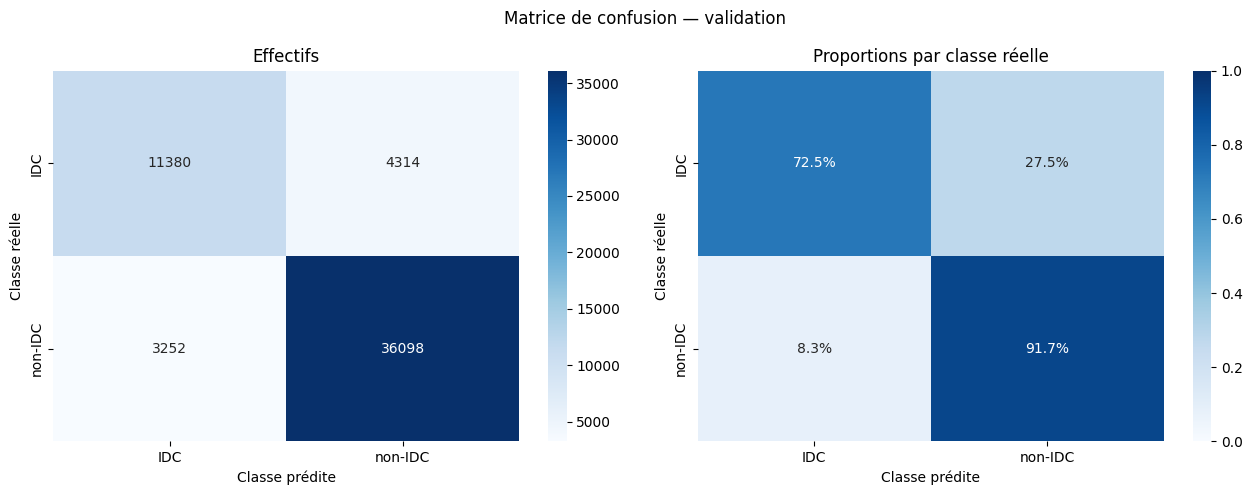

IDC positif : VP = 11,380 | FN = 4,314 | FP = 3,252 | VN = 36,098


In [14]:
supports = cm.sum(axis=1)
cm_normalized = np.divide(
    cm, supports[:, None],
    out=np.full(cm.shape, np.nan, dtype=float),
    where=supports[:, None] != 0,
)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
sns.heatmap(cm_normalized, annot=True, fmt=".1%", cmap="Blues",
            vmin=0, vmax=1, mask=np.isnan(cm_normalized),
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
for ax, title in zip(axes, ["Effectifs", "Proportions par classe réelle"]):
    ax.set(title=title, xlabel="Classe prédite", ylabel="Classe réelle")
plt.suptitle("Matrice de confusion — validation")
plt.tight_layout()
plt.show()

vp = int(cm[idc_index, idc_index])
fn = int(cm[idc_index, non_idc_index])
fp = int(cm[non_idc_index, idc_index])
vn = int(cm[non_idc_index, non_idc_index])
print(f"IDC positif : VP = {vp:,} | FN = {fn:,} | FP = {fp:,} | VN = {vn:,}")


## 10. Métriques par classe et bilan chiffré

Cette section réutilise la matrice précédente, sans nouvelle prédiction.

- **Précision** : parmi les images prédites dans une classe, proportion de prédictions correctes.
- **Rappel** : parmi les images réellement dans cette classe, proportion retrouvée.
- **F1** : moyenne harmonique de la précision et du rappel.
- **Support** : nombre d’images réellement présentes dans chaque classe.
- **Balanced accuracy** : moyenne des rappels des deux classes ; chaque classe a le même poids.

Une métrique dont le dénominateur est nul est indiquée « non défini », et non assimilée à zéro. La référence majoritaire correspond à l’accuracy obtenue en prédisant toujours la classe la plus fréquente de cette validation : c’est un repère descriptif, pas un modèle entraîné.

IDC — support : 15,694 | précision : 77.77% | rappel : 72.51% | F1 : 75.05%
non-IDC — support : 39,350 | précision : 89.32% | rappel : 91.74% | F1 : 90.51%


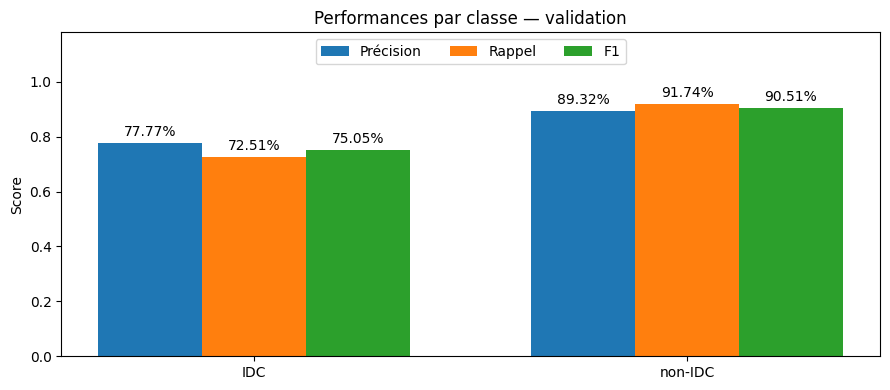

Accuracy : 86.25%
Référence majoritaire : 71.49%
Balanced accuracy : 82.12% | F1 macro : 82.78%
Rappel IDC : 72.51%
Faux négatifs IDC : 4,314 sur 15,694 images IDC.


In [15]:
def safe_ratio(numerator, denominator):
    return numerator / denominator if denominator else np.nan

def format_rate(value):
    return f"{value:.2%}" if np.isfinite(value) else "non défini"

class_metrics = []
for index, name in enumerate(class_names):
    tp = int(cm[index, index])
    actual = int(cm[index, :].sum())
    predicted_count = int(cm[:, index].sum())
    precision = safe_ratio(tp, predicted_count)
    recall = safe_ratio(tp, actual)
    f1 = safe_ratio(2 * tp, actual + predicted_count)
    class_metrics.append([precision, recall, f1])
    print(f"{name} — support : {actual:,} | précision : {format_rate(precision)} | "
          f"rappel : {format_rate(recall)} | F1 : {format_rate(f1)}")

class_metrics = np.asarray(class_metrics)
balanced_accuracy = float(np.mean(class_metrics[:, 1]))
macro_f1 = float(np.mean(class_metrics[:, 2]))
majority_accuracy = float(supports.max() / n_images)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(class_names))
width = 0.24
for j, label in enumerate(["Précision", "Rappel", "F1"]):
    bars = ax.bar(x + (j - 1) * width, class_metrics[:, j], width, label=label)
    ax.bar_label(bars, labels=[format_rate(v) for v in class_metrics[:, j]], padding=3)
ax.set_xticks(x, class_names)
ax.set(ylim=(0, 1.18), ylabel="Score", title="Performances par classe — validation")
ax.legend(loc="upper center", ncol=3)
plt.tight_layout()
plt.show()

print(f"Accuracy : {format_rate(validation_accuracy)}")
print(f"Référence majoritaire : {format_rate(majority_accuracy)}")
print(f"Balanced accuracy : {format_rate(balanced_accuracy)} | F1 macro : {format_rate(macro_f1)}")
print(f"Rappel IDC : {format_rate(class_metrics[idc_index, 1])}")
print(f"Faux négatifs IDC : {fn:,} sur {supports[idc_index]:,} images IDC.")


## 11. Interprétation des résultats

Compléter cette analyse après exécution avec les chiffres et courbes de l’expérience. Aucun résultat numérique n’est présupposé.

1. **Apprentissage :** les pertes diminuent-elles ? À partir de quelle époque les courbes divergent-elles ? Comparer la dernière époque à celle de perte de validation minimale avant de discuter un éventuel surapprentissage.
2. **Performance globale :** comparer l’accuracy à la référence majoritaire, puis à la balanced accuracy. Un écart entre accuracy et balanced accuracy invite à examiner les effectifs et les rappels par classe.
3. **Détection IDC :** relever le rappel IDC et le nombre de faux négatifs. Examiner également la précision et les faux positifs pour décrire les deux types d’erreur.
4. **Limites :** les résultats portent sur des fragments et sur la validation utilisée pendant l’entraînement. Le découpage actuel par image ne garantit pas une séparation des patients.
5. **Suite des expériences :** selon les observations, tester une régularisation si les courbes suggèrent du surapprentissage, ou un traitement du déséquilibre si une classe est moins bien reconnue. Comparer les essais avec un protocole identique, puis évaluer le modèle retenu sur un test indépendant séparé par patient.

**Trame de conclusion à renseigner :**

> Après … époques, le modèle obtient une accuracy de validation de …, contre … pour la référence majoritaire, et une balanced accuracy de …. Le rappel IDC est de …, avec … faux négatifs sur … fragments IDC. Les courbes montrent …. Ces résultats restent à confirmer sur un jeu de test indépendant, séparé par patient.

L’AUC ROC évoquée dans la démarche expérimentale n’est pas calculée ici : elle nécessite les scores de prédiction à différents seuils, que la matrice de confusion seule ne fournit pas.